<a href="https://colab.research.google.com/github/UL0222199/Podstawy_SI/blob/main/lab_neuron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium: perceptron i Adaline

**Podstawy AI**

Dziś zbudujesz od zera dwa najprostsze modele, które *uczą się z danych*. Oba szukają **prostej**, która oddziela dwie klasy punktów, ale uczą się inaczej:

- **perceptron** (Rosenblatt, 1957) uczy się na swoich pomyłkach,
- **Adaline** (Widrow i Hoff, 1960) minimalizuje **funkcję straty** metodą **spadku gradientu**.

**Część I — perceptron:** implementacja, sprawdzenie z kartką, Iris, rola $\eta$, dane nierozdzielne.
**Część II — Adaline:** implementacja, za duże i za małe $\eta$, $\eta$ × liczba epok, granica decyzyjna w czasie.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=4, suppress=True)

# Część I: perceptron

## 1. Implementacja

Neuron liczy **pobudzenie** $z = \mathbf{w}^T\mathbf{x} + b$ i zamienia je na klasę funkcją skokową: $\hat y = 1$, gdy $z \ge 0$, w przeciwnym razie $\hat y = 0$.

**Uczenie.** Dla każdego przykładu $\mathbf{x}^{(i)}$ po kolei:
1. liczymy predykcję $\hat{y}^{(i)}$ (raz, na obecnych wagach),
2. liczymy błąd $e = y^{(i)} - \hat{y}^{(i)}$ (prawdziwa klasa **minus** przewidziana),
3. poprawiamy wszystkie wagi i bias: $\quad w_j := w_j + \eta\, e\, x_j^{(i)}, \qquad b := b + \eta\, e$

### Zadanie 1 — uzupełnij metodę `fit`

Brakuje **trzech linijek** w pętli uczącej: obliczenia poprawki `update` $= \eta \cdot e$ i dodania jej do wag `self.w_` oraz biasu `self.b_`.

Wskazówki:
- `xi` to wektor cech jednego przykładu, `target` to jego prawdziwa klasa $y$,
- `self.predict(xi)` zwraca predykcję $\hat{y}$,
- `update * xi` mnoży poprawkę przez *każdą* cechę naraz, więc poprawia wszystkie wagi jednocześnie.

Parametr `verbose=True` wypisuje każdy krok uczenia, tak jak w tabelce na kartce.

In [2]:
class Perceptron:
    """Klasyfikator perceptronowy (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia (0.0 – 1.0)
    n_iter : int       liczba epok
    w_init : str       'zeros' (wagi startowe = 0) albo 'random' (małe losowe)
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać każdy krok uczenia

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  errors_ : liczba pomyłek w każdej epoce
    """

    def __init__(self, eta=0.1, n_iter=10, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        n_cech = X.shape[1]
        if self.w_init == "zeros":
            self.w_ = np.zeros(n_cech)
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=n_cech)
        self.b_ = 0.0
        self.errors_ = []

        for epoka in range(1, self.n_iter + 1):
            bledy = 0
            for xi, target in zip(X, y):
                if self.verbose:
                    w_przed, b_przed = self.w_.copy(), self.b_
                    z, y_hat = self.net_input(xi), self.predict(xi)
                # TODO: uzupełnij trzy linijki
                update = self.eta * (target - self.predict(xi))        # η · (y − ŷ)
                self.w_ += update * xi
                self.b_ += update
                bledy += int(update != 0.0)
                if self.verbose:
                    print(f"epoka {epoka} | x={xi} y={target} | w={w_przed} b={b_przed:5.2f} "
                          f"| z={z:6.2f} ŷ={y_hat} | update={update:+.2f}")
            self.errors_.append(bledy)
            if self.verbose:
                print(f"--- koniec epoki {epoka}: pomyłek {bledy}, w={self.w_}, b={self.b_:.2f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def predict(self, X):
        """Funkcja skokowa: 1 jeśli z >= 0, w przeciwnym razie 0"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

## 2. Sprawdzenie na przykładzie z kartki

| punkt | $x_1$ | $x_2$ | $y$ |
|---|---|---|---|
| A | 2 | 1 | 1 |
| B | 1 | 3 | 0 |
| C | 3 | 2 | 1 |
| D | 0 | 2 | 0 |

Start $w_1 = w_2 = b = 0$, $\eta = 1$. **Wypisane kroki muszą zgadzać się z Twoją tabelką na kartce.**

In [3]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

p = Perceptron(eta=1.0, n_iter=3, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1 | x=[2. 1.] y=1 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 3.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-1.00
epoka 1 | x=[3. 2.] y=1 | w=[-1. -3.] b=-1.00 | z=-10.00 ŷ=0 | update=+1.00
epoka 1 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 1: pomyłek 2, w=[ 2. -1.], b=0.00
epoka 2 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 2 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 2 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 2 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 2: pomyłek 0, w=[ 2. -1.], b=0.00
epoka 3 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 3 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 3 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 3 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | upd

In [4]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
assert np.allclose(p.w_, [2, -1]) and np.isclose(p.b_, 0), f"Coś nie tak: w={p.w_}, b={p.b_}"
assert p.errors_ == [2, 0, 0]
print("✅ Wynik zgodny z kartką: w =", p.w_, " b =", p.b_)

✅ Wynik zgodny z kartką: w = [ 2. -1.]  b = 0.0


**Pytanie 1.** Po aktualizacji na punkcie B punkt C ma $z = -10$, czyli jest bardzo źle sklasyfikowany (zobacz wydruk). Co to mówi o sposobie, w jaki uczy się perceptron?

✍️ **Twoja odpowiedź:**

Mówi to, że perceptron początkowo nie ma żadnego pojęcia jak klasyfikować i początkowa predykcja jest prawie losowa, choć jak zła by nie była, z każdą kolejną iteracją perceptron będzie zbliżał się do poprawnej funkcji klasyfikującej.

## 3. Perceptron na danych Iris

Bierzemy dwa gatunki: **setosa** (klasa 0) i **versicolor** (klasa 1), czyli pierwsze 100 kwiatów, oraz dwie cechy: długość działki kielicha (kolumna 0) i długość płatka (kolumna 2).

In [5]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1
print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))


def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("setosa", "versicolor")):
    # Koloruje płaszczyznę według klasy przewidywanej przez model (gotowe, nie trzeba zmieniać)
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))
    Z = model.predict(np.array([xx1.ravel(), xx2.ravel()]).T).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker, edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


### Zadanie 2
Naucz perceptron `ppn` (`eta=0.1`, `n_iter=10`) na `X`, `y`. Narysuj obok siebie liczbę pomyłek w każdej epoce (`ppn.errors_`) i regiony decyzyjne. (Model `ppn` przyda się jeszcze w części II.)

[2, 2, 3, 2, 1, 0, 0, 0, 0, 0]


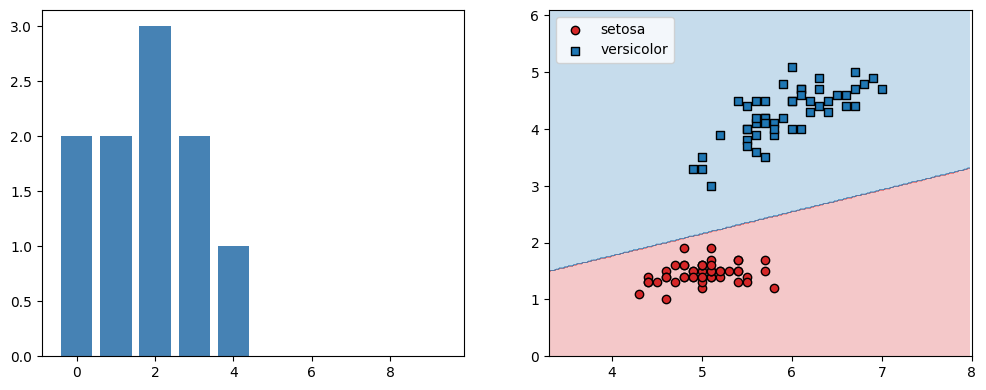

In [6]:
# TODO: utwórz perceptron ppn i naucz go na X, y
ppn = Perceptron(eta=0.1, n_iter=10, verbose=False).fit(X, y)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
# TODO: axs[0]: liczba pomyłek w epokach
# TODO: axs[1]: plot_decision_regions(X, y, ppn, ax=axs[1])
print(ppn.errors_)
axs[0].bar(np.arange(len(ppn.errors_)), ppn.errors_, color='steelblue')
plot_decision_regions(X, y, ppn, ax=axs[1])
plt.show()

**Pytanie 2.** Po ilu epokach perceptron przestał się mylić? Czy granica leży „w środku” między klasami, czy blisko jednej z nich? Dlaczego?

✍️ **Twoja odpowiedź:** ...

Perceptron przestał się mylić po 5 epoce. Granica leży blisko klasy versicolor, ponieważ perceptron kończy poprawiać wagi od razu gdy przestanie się mylić, znajduje pierwsze działające rozwiązanie, nie najlepsze.

### Czy $\eta$ ma znaczenie?

Uczymy perceptron z $\eta \in \{0.0001,\ 0.01,\ 0.1,\ 1\}$, startując od **zerowych wag**.

**Przewiduję:** przy którym $\eta$ perceptron nauczy się najszybciej?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** 0.1

In [7]:
for eta in [0.0001, 0.01, 0.1, 1.0]:
    p = Perceptron(eta=eta, n_iter=10, w_init="zeros").fit(X, y)
    print(f"η = {eta:<7} pomyłki: {p.errors_}   w/η = {p.w_ / eta},  b/η = {p.b_ / eta:.2f}")

η = 0.0001  pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.01    pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.1     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 1.0     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00


**Pytanie 3.** Liczba pomyłek jest identyczna, a `w/η` wychodzi tak samo dla każdego $\eta$. Dlaczego? Wskazówka: od czego zależy $\hat y$ — od wartości $z$ czy tylko od jej znaku?

✍️ **Twoja odpowiedź:** $\hat y$ zależy wyłącznie od znaku z, η skaluje wagę, ale nie ma znikomy wpływ na znak. Jedynie gdybyśmy zaczynali z wagami innymi niż 0, η określałby jak szybko wagi będą się zmieniać, choć miałoby to znaczenie jedynie na początku.

## 4. Gdy klas nie da się rozdzielić prostą

Inna para gatunków: **versicolor** (klasa 0) i **virginica** (klasa 1), kwiaty 50–149, te same cechy.

### Zadanie 3
1. Utwórz `X2` (kwiaty 50–149, kolumny 0 i 2) i `y2` (1 dla virginica; virginica ma w `iris.target` wartość 2).
2. **Przetasuj dane** (kod podany): w Iris kwiaty są posortowane według gatunku, a bez tasowania perceptron widzi 50 kwiatów jednej klasy z rzędu i dopasowuje się tylko do ostatnio oglądanej.
3. Naucz perceptron (`eta=0.1`, `n_iter=30`), narysuj liczbę pomyłek w epokach i regiony decyzyjne.
4. Policz pomyłki **nauczonego modelu** na całym zbiorze: `(ppn2.predict(X2) != y2).sum()`.

**Przewiduję:** po ilu epokach perceptron przestanie się mylić?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Nie przestanie się mylić

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]
[45, 30, 30, 30, 22, 28, 19, 22, 21, 22, 19, 17, 15, 15, 15, 15, 17, 15, 17, 17, 15, 17, 21, 19, 21, 19, 17, 19, 15, 15]


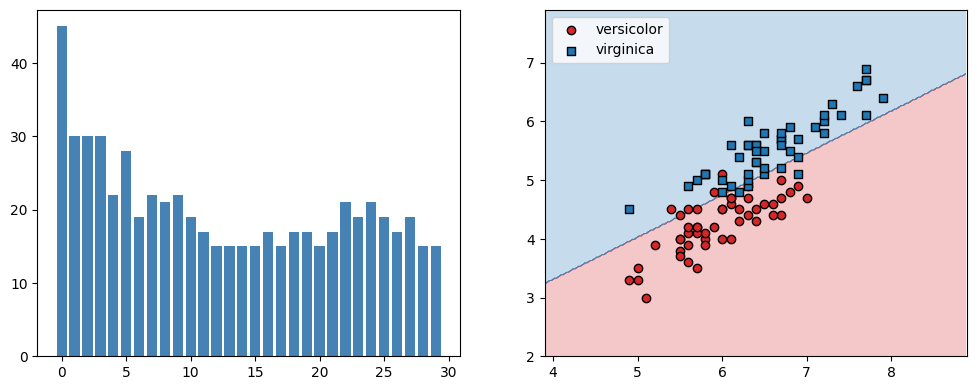

np.int64(10)

In [8]:
# TODO: dane
X2 = iris.data[50:149][:, [0, 2]]
y2 = (iris.target[50:149] == 2).astype(int)
print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

# tasowanie (gotowe): ta sama losowa kolejność dla X2 i y2
idx = np.random.RandomState(0).permutation(len(y2))
X2, y2 = X2[idx], y2[idx]

# TODO: perceptron ppn2, 30 epok, wykres pomyłek i regionów decyzyjnych
ppn2 = Perceptron(eta=0.1, n_iter=30, verbose=False).fit(X2, y2)

print(ppn2.errors_)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].bar(np.arange(len(ppn2.errors_)), ppn2.errors_, color='steelblue')
plot_decision_regions(X2, y2, ppn2, ax=axs[1], etykiety=("versicolor", "virginica"))
plt.show()

# TODO: liczba pomyłek nauczonego modelu
(ppn2.predict(X2) != y2).sum()

**Pytanie 4.** Czy perceptron kiedykolwiek przestaje się mylić? Co dzieje się z wagami? Dlaczego liczba pomyłek *w trakcie* epoki (`errors_`) różni się od liczby pomyłek *nauczonego modelu*?

✍️ **Twoja odpowiedź:** ...

Perceptron nigdy nie przestaje się mylić. Waga `w1` rośnie w dół, a `w2` w górę, ostatecznie znak `z` ciągle oscyluje. Liczba pomyłek w trakcie epoki różni się od liczby pomyłek *nauczonego modelu*, ponieważ w trakcie epoki wagi ciągle się zmieniają, a nauczony model operuje na zamrożonym zestawie wag.

# Część II: Adaline

## 5. Implementacja

Adaline liczy to samo $z = \mathbf{w}^T\mathbf{x} + b$, ale błąd bierze z **ciągłego** $z$, a nie z $\hat y$:

| | perceptron | Adaline |
|---|---|---|
| błąd | $y - \hat{y} \in \{0, \pm 1\}$ | $y - z$, dowolna liczba |
| poprawka | po każdym przykładzie | raz na epokę, z całego zbioru |
| predykcja | $\hat y = 1$, gdy $z \ge 0$ | $\hat y = 1$, gdy $z \ge 0.5$ |

Adaline minimalizuje **funkcję straty** (średni błąd kwadratowy):

$$L(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y^{(i)} - z^{(i)}\right)^2$$

metodą **spadku gradientu** (wyprowadzenie w dodatku prezentacji):

$$w_j := w_j + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad b := b + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

### Zadanie 4 — uzupełnij metodę `fit`

Brakuje **czterech linijek**:
1. `errors` — wektor błędów $y - z$ dla **wszystkich** przykładów naraz (`output` jest już policzone),
2. aktualizacja wag `self.w_` (sumę $\sum_i e^{(i)} x_j^{(i)}$ dla wszystkich $j$ naraz liczy `X.T @ errors`, a $n$ to `X.shape[0]`),
3. aktualizacja biasu `self.b_`,
4. `loss` — średni błąd kwadratowy w tej epoce.

In [9]:
class AdalineGD:
    """ADAptive LInear NEuron, uczony pełnym spadkiem gradientu (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia
    n_iter : int       liczba epok
    w_init : str       'random' (małe losowe, jak u Raschki) albo 'zeros'
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać stan po każdej epoce

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  losses_ : wartość MSE w każdej epoce
    """

    def __init__(self, eta=0.01, n_iter=50, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        if self.w_init == "zeros":
            self.w_ = np.zeros(X.shape[1])
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_ = []

        for epoka in range(1, self.n_iter + 1):
            net_input = self.net_input(X)          # z dla WSZYSTKICH przykładów naraz
            output = self.activation(net_input)    # Adaline: aktywacja liniowa, output = z
            # TODO: uzupełnij cztery linijki
            errors = y - net_input            # y − z
            self.w_ += self.eta * (2 / len(y)) * X.T @ errors        # η · 2/n · X.T @ errors
            self.b_ += self.eta * (2 / len(y)) * np.sum(errors)       # η · 2 · średnia błędów
            loss = np.sum(np.power(errors, 2)) / len(errors)              # MSE
            self.losses_.append(loss)
            if self.verbose:
                print(f"epoka {epoka}: z = {output}, błędy = {errors}, "
                      f"MSE = {loss:.4f} -> nowe w = {self.w_}, b = {self.b_:.4f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def activation(self, X):
        """Liniowa funkcja aktywacji: sigma(z) = z"""
        return X

    def predict(self, X):
        """Klasa po progu 0.5"""
        return np.where(self.activation(self.net_input(X)) >= 0.5, 1, 0)

**Test na punktach A–D** (start od zera, $\eta = 0.05$). Na starcie $z = 0$, więc błędy to $(1, 0, 1, 0)$ i MSE $= 0.5$. Po pierwszej epoce powinno wyjść $w = (0.125,\ 0.075)$, $b = 0.05$, a strata w drugiej epoce $\approx 0.193$.

In [10]:
ada_k = AdalineGD(eta=0.05, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

ada_1 = AdalineGD(eta=0.05, n_iter=1, w_init="zeros").fit(X_kartka, y_kartka)
assert np.allclose(ada_1.w_, [0.125, 0.075]) and np.isclose(ada_1.b_, 0.05), f"Po 1. epoce: w={ada_1.w_}, b={ada_1.b_}"
assert np.allclose(ada_k.losses_, [0.5, 0.1928125]), f"Straty: {ada_k.losses_}"
print("✅ Implementacja poprawna")
print("z po 1. epoce:", ada_1.net_input(X_kartka), "  predykcje:", ada_1.predict(X_kartka), "  prawdziwe:", y_kartka)

epoka 1: z = [0. 0. 0. 0.], błędy = [1. 0. 1. 0.], MSE = 0.5000 -> nowe w = [0.125 0.075], b = 0.0500
epoka 2: z = [0.375 0.4   0.575 0.2  ], błędy = [ 0.625 -0.4    0.425 -0.2  ], MSE = 0.1928 -> nowe w = [0.1781 0.0719], b = 0.0612
✅ Implementacja poprawna
z po 1. epoce: [0.375 0.4   0.575 0.2  ]   predykcje: [0 0 1 0]   prawdziwe: [1 0 1 0]


**Pytanie 5.** Po pierwszej epoce punkt B ma $z = 0.4$, więc jest klasyfikowany poprawnie ($< 0.5$). Mimo to w drugiej epoce wnosi do poprawki błąd $-0.4$. Perceptron nie zmieniłby wag z powodu B. Dlaczego Adaline to robi?

✍️ **Twoja odpowiedź:**

Ponieważ zadaniem Adaline jest minimalizowanie średniego błędu kwadratowego, czyli szuka najlepszego rozwiązania, nie jedynie pierwszego wystarczającego.

## 6. Za duże i za małe $\eta$

Uczymy Adaline na Iris (setosa i versicolor) przez 15 epok z $\eta = 0.1$ i $\eta = 0.0001$.

**Przewiduję:** jak będzie wyglądała strata w obu przypadkach? Czy $\eta$ ma tu znaczenie, tak jak w perceptronie, czy nie?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** η ma znaczenie, przy mniejszym η strata będzie się wolniej zwiększała, choć pozwala osiągnąć większą dokładność na końcu.

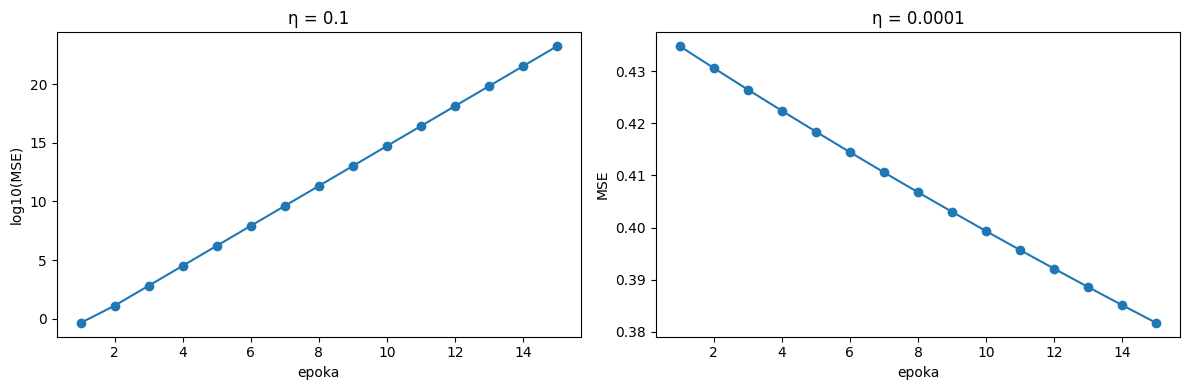

η = 0.1:    MSE w epokach 1, 2, 3: [  0.43  12.99 648.81]  ... w 15.: 1.7e+23
η = 0.0001: MSE w 1. i 15. epoce:  0.435 0.382


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ada1 = AdalineGD(eta=0.1, n_iter=15).fit(X, y)
axs[0].plot(range(1, 16), np.log10(ada1.losses_), marker="o")
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("log10(MSE)"); axs[0].set_title("η = 0.1")
ada2 = AdalineGD(eta=0.0001, n_iter=15).fit(X, y)
axs[1].plot(range(1, 16), ada2.losses_, marker="o")
axs[1].set_xlabel("epoka"); axs[1].set_ylabel("MSE"); axs[1].set_title("η = 0.0001")
plt.tight_layout(); plt.show()
print("η = 0.1:    MSE w epokach 1, 2, 3:", np.round(ada1.losses_[:3], 2), " ... w 15.:", f"{ada1.losses_[-1]:.1e}")
print("η = 0.0001: MSE w 1. i 15. epoce: ", round(ada2.losses_[0], 3), round(ada2.losses_[-1], 3))

**Pytanie 6.** Co się stało w obu przypadkach? (Lewy wykres ma skalę logarytmiczną: 20 oznacza stratę $10^{20}$.)

✍️ **Twoja odpowiedź:**

Przy η = 0.1, średni błąd kwadratowy bardzo silnie zwiększa się z każdą epoką. Przy η = 0.0001 MSE zmniejsza się z każdą epoką, choć relatywnie nieznacznie. Oznacza to, że η nie wpływa jedynie na prędkość zmiejszania się błędu, ale zbyt duże może powodać jego zwiększanie.

### Zadanie 5: granica stabilności

Ucz Adaline przez **100 epok** dla $\eta \in \{0.001,\ 0.01,\ 0.02,\ 0.022,\ 0.024,\ 0.025,\ 0.026,\ 0.03\}$. Dla każdego $\eta$ wypisz MSE w 1. i 100. epoce oraz trafność. Znajdź największe $\eta$, przy którym strata jeszcze **maleje**. (`np.errstate` wycisza ostrzeżenia o przepełnieniu przy dużych $\eta$.)

In [12]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02, 0.022, 0.024, 0.025, 0.026, 0.03]:
        # TODO: naucz AdalineGD (100 epok) i wypisz: eta, MSE w 1. i 100. epoce, trafność
        model =  AdalineGD(eta=eta, n_iter=100).fit(X, y)
        print(f"{"Eta":8} | {eta:.3f}")
        print(f"{"MSE":8} | {model.losses_[0]} | {model.losses_[99]:.4f}")
        accuracy = np.mean(model.predict(X) == y)
        print(f"{"Trafność":8} | {accuracy:.0%}\n")

Eta      | 0.001
MSE      | 0.4347694479212059 | 0.1202
Trafność | 100%

Eta      | 0.010
MSE      | 0.4347694479212059 | 0.0144
Trafność | 100%

Eta      | 0.020
MSE      | 0.4347694479212059 | 0.0124
Trafność | 100%

Eta      | 0.022
MSE      | 0.4347694479212059 | 0.0124
Trafność | 100%

Eta      | 0.024
MSE      | 0.4347694479212059 | 0.0124
Trafność | 100%

Eta      | 0.025
MSE      | 0.4347694479212059 | 32.3564
Trafność | 50%

Eta      | 0.026
MSE      | 0.4347694479212059 | 112392214.8220
Trafność | 50%

Eta      | 0.030
MSE      | 0.4347694479212059 | 1399312213035413453041706205184.0000
Trafność | 50%



**Pytanie 7.** Gdzie leży granica stabilności dla tych danych?

✍️ **Twoja odpowiedź:** Granica stablinośći leży w okolicy η = 0.024. Zwiększenie tej liczby poza tę granicę skutkuje zwiększaniem się MSE.

## 7. $\eta$ × liczba epok

Czy za małe $\eta$ da się nadrobić większą liczbą epok? A za duże?

### Zadanie 6
Dla $\eta \in \{0.001,\ 0.01,\ 0.02,\ 0.025\}$ i liczby epok $\in \{15,\ 100,\ 1000\}$ naucz Adaline i wypisz tabelę: MSE w ostatniej epoce i trafność.

**Przewiduję:** czy $\eta = 0.001$ po 1000 epokach dogoni $\eta = 0.01$ po 100 epokach?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Tak, dogoni.

In [13]:
print("η        " + "".join(f"{n:>16} epok" for n in [15, 100, 1000]))
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02, 0.025]:
        wiersz = f"{eta:<8} "
        for n in [15, 100, 1000]:
            # TODO: naucz AdalineGD(eta=eta, n_iter=n), dopisz do wiersza MSE i trafność,
            #       np. wiersz += f"{mse:>14.3g} / {traf:>5.0%}"
            model =  AdalineGD(eta=eta, n_iter=n).fit(X, y)
            mse = model.losses_[n - 1]
            traf = np.mean(model.predict(X) == y)
            wiersz += f"{mse:>14.3g} / {traf:>5.0%}"
        print(wiersz)

η                      15 epok             100 epok            1000 epok
0.001             0.193 /   74%          0.12 /  100%        0.0144 /  100%
0.01              0.102 /  100%        0.0144 /  100%        0.0124 /  100%
0.02             0.0596 /  100%        0.0124 /  100%        0.0123 /  100%
0.025             0.553 /   50%          32.4 /   50%       4.2e+20 /   50%


**Pytanie 8.**
1. Ile epok potrzebuje $\eta = 0.001$, żeby dojść tam, gdzie $\eta = 0.01$ po 100 epokach?
2. Czy strata spada do zera? Co się dzieje, gdy dojdzie do „dna”?
3. Czy więcej epok pomaga przy $\eta = 0.025$?
4. Trafność 100% pojawia się dużo wcześniej niż „dno” straty. Co to znaczy?

✍️ **Twoja odpowiedź:**

1. $\eta = 0.001$ potrzebuje 1000 epok, żeby dojść tam, gdzie $\eta = 0.01$ dochodzi po 100 epokach.
2. Strata nie spada do zera, choć zbliża się do minimum funkcji błędu (dna). Możliwe jest, że osiągnie absolutne minimum (gdy gradient wynosi zero -> wagi przestają się zmieniać) albo będzie oscylować wokół dna.
3. Nie, a wręcz błąd zwiększa się wraz ze wzrostem liczby epok.
4. Oznacza to, że Adaline nie zatrzymuje się przy braku błędów.

## 8. Granica decyzyjna w czasie

Granica Adaline to prosta $z = 0.5$, czyli $x_2 = \dfrac{0.5 - b - w_1 x_1}{w_2}$. Granica perceptronu to $z = 0$, czyli $x_2 = -\dfrac{b + w_1 x_1}{w_2}$.

### Zadanie 7
Narysuj punkty Iris oraz granice Adaline ($\eta = 0.01$) po $1, 5, 20, 100$ i $1000$ epokach. Dla każdej liczby epok wypisz wagi, bias i trafność. Dorysuj granicę perceptronu `ppn` z zadania 2 (linia przerywana).

N = 1
Wagi: [0.0678 0.0324]
Bias: 0.008572688322970255
Trafność: 95%

N = 5
Wagi: [0.0658 0.0681]
Bias: 0.0057675424732272565
Trafność: 100%

N = 20
Wagi: [0.0202 0.1545]
Bias: -0.009796217508847254
Trafność: 100%

N = 100
Wagi: [-0.0754  0.3356]
Bias: -0.04113988160522199
Trafność: 100%

N = 1000
Wagi: [-0.0994  0.3735]
Bias: -0.0262036983946289
Trafność: 100%



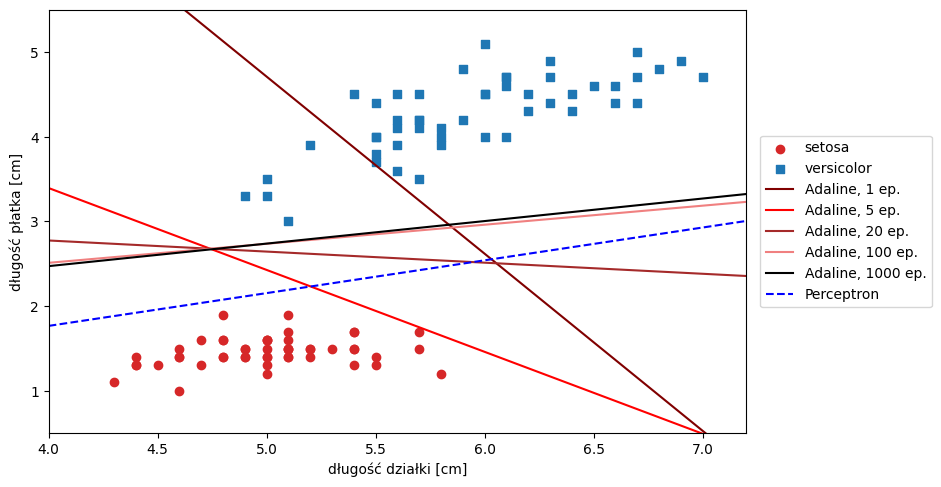

In [14]:
x1 = np.linspace(4.0, 7.2, 2)
plt.figure(figsize=(9, 5.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:red", marker="o", label="setosa")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", marker="s", label="versicolor")

colors = ['black', 'lightcoral', 'brown', 'red', 'maroon']

for n in [1, 5, 20, 100, 1000]:
    # TODO: naucz AdalineGD(eta=0.01, n_iter=n), wypisz wagi, bias i trafność,
    #       narysuj prostą x2 = (0.5 - b - w1*x1) / w2 z etykietą f"Adaline, {n} ep."
    model =  AdalineGD(eta=0.01, n_iter=n).fit(X, y)
    print(f"N = {n}")
    print(f"Wagi: {model.w_}")
    print(f"Bias: {model.b_}")
    print(f"Trafność: {np.mean(model.predict(X) == y):.0%}\n")
    plt.plot(x1, ((0.5 - model.b_ - model.w_[0] * x1) / model.w_[1]),
             color=colors.pop(),
             label=f"Adaline, {n} ep."
    )

# TODO: granica perceptronu ppn: x2 = -(b + w1*x1) / w2, linia "k--"
plt.plot(x1, -((ppn.b_ + ppn.w_[0] * x1) / ppn.w_[1]),
            color='blue', label="Perceptron", ls = '--'
)

plt.xlim(4.0, 7.2); plt.ylim(0.5, 5.5)
plt.xlabel("długość działki [cm]"); plt.ylabel("długość płatka [cm]")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.show()

**Pytanie 9.** Od której epoki trafność wynosi 100%? Co dzieje się z prostą później i dlaczego? Czym różni się końcowa granica Adaline od granicy perceptronu?

✍️ **Twoja odpowiedź:** Trafność wynosi 100% już od 5 epoki, później prosta przesuwa się tak by minimalizować średni błąd kwadratowy. Końcowa granica Adaline jest wyżej od granicy perceptronu.

## 9. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Czym różni się błąd w Adaline od błędu w perceptronie? Błąd w perceptronie jest zero-jedynkowy, perceptron kończy naukę gdy przestaje się mylić. W Adaline to liczba, która powinna dążyć do minimum funkcji straty. Adaline stara się ją zmniejszać nawet bez pomyłek i radzi sobie w sytuacjach, gdy dane nachodzą na siebie i nie da się uzyskać błędu = 0.
2. Co to jest funkcja straty i co znaczy „uczenie” w Adaline? Funkcja straty wyznacza średni błąd kwadratowy (MSE) w danej epoce. Uczenie w Adaline polega na takim modyfikowaniu wag (metodą spadku gradientu) by MSE w każdej kolejnej epoce był coraz bliższy 0.
3. Dlaczego w Adaline $\eta$ ma duże znaczenie, a w perceptronie (przy starcie od zera) nie miało? W perceptronie liczyło się jedynie to czy znak `z` jest ujemny czy dodatni, $\eta$ nie wpływała na znak. W Adaline, $\eta$ realnie wyznacza jak szybko wagi będą się zmieniać.
4. Czy za małe $\eta$ można nadrobić liczbą epok? A za duże? Małe $\eta$ - można nadrobić liczbą epok, ale przy zbyt dużym $\eta$ metoda gradientu zaczyna "przestrzelać" i MSE zwiększa się zamiast zmniejszać.
5. Kiedy perceptron się zatrzymuje, a kiedy Adaline? Perceptron zatrzymuje się, gdy błąd dla każdego "punktu" wynosi 0. Adaline zatrzymuje się najczęściej po zadeklarowanej liczbie epok.

---
## Zadanie dodatkowe (na ocenę 4/5)

1. **versicolor vs virginica** (`X2`, `y2` z zadania 3). Naucz Adaline dla $\eta \in \{0.001,\ 0.01,\ 0.02\}$ przez 1000 epok. Wypisz MSE i trafność, narysuj stratę i regiony decyzyjne dla najlepszego $\eta$. Czy uczenie się stabilizuje? Porównaj z perceptronem z zadania 3. Czy granica stabilności jest taka sama jak dla setosa/versicolor?
2. **XOR** (punkty $(0,0), (1,0), (0,1), (1,1)$, etykiety $0, 1, 1, 0$). Naucz perceptron (`w_init="zeros"`, 20 epok) i Adaline (`w_init="zeros"`, $\eta = 0.1$, 500 epok). Co robi każdy z nich? Dlaczego żaden nie daje rady?

Eta      | 0.001
MSE      | 0.1532
Trafność | 55%

Eta      | 0.010
MSE      | 0.0783
Trafność | 54%

Eta      | 0.020
MSE      | inf
Trafność | 50%



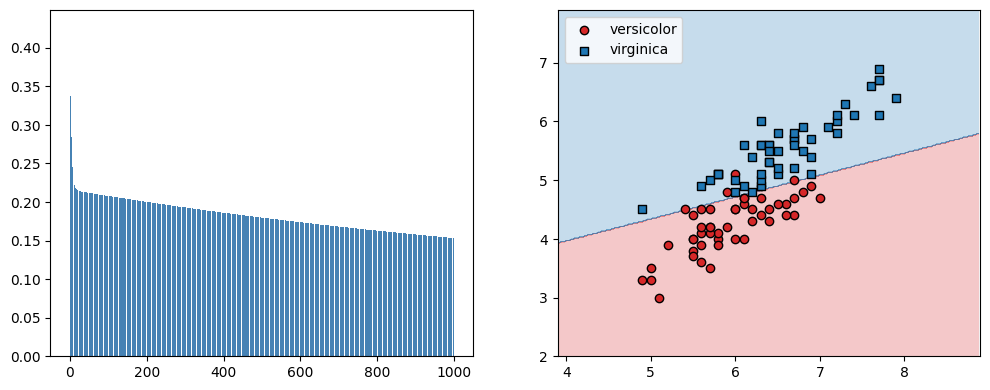

In [23]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02]:
        model =  AdalineGD(eta=eta, n_iter=1000).fit(X2, y2)
        print(f"{"Eta":8} | {eta:.3f}")
        print(f"{"MSE":8} | {model.losses_[999]:.4f}")
        accuracy = np.mean(model.predict(X) == y)
        print(f"{"Trafność":8} | {accuracy:.0%}\n")

best_model =  AdalineGD(eta=0.001, n_iter=1000).fit(X2, y2)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].bar(np.arange(len(best_model.losses_)), best_model.losses_, color='steelblue')
plot_decision_regions(X2, y2, best_model, ax=axs[1], etykiety=("versicolor", "virginica"))
plt.show()

Ad. 1. Uczenie się stabilizuje na poziomie trafności ok. 55%, choć nadal minimalnie spada nawet po 1000 epok. W perceptronie trafność oscylowała na przestrzeni epok. Granica stabilności jest już przekroczona dla $\eta$ = 0.02, szybciej niż dla setosa/versicolor gdzie granica była w $\eta$ = 0.024.

In [34]:
X_XOR = np.array([(0,0),(1,0),(0,1),(1,1)])
y_XOR = np.array([0, 1, 1, 0])

print("Model: Perceptron")
ppn_xor = Perceptron(eta=1.0, n_iter=20, w_init="zeros").fit(X_XOR, y_XOR)
print(f"Wagi: {ppn_xor.w_}")
print(f"Bias: {ppn_xor.b_}")
print(f"Trafność: {np.mean(ppn_xor.predict(X) == y):.0%}\n")

print("Model: Adaline")
adaline_xor = AdalineGD(eta=0.1, n_iter=500, w_init="zeros", verbose=False).fit(X_XOR, y_XOR)
print(f"Wagi: {adaline_xor.w_}")
print(f"Bias: {adaline_xor.b_}")
print(f"Trafność: {np.mean(adaline_xor.predict(X) == y):.0%}\n")

Model: Perceptron
Wagi: [ 0. -1.]
Bias: 0.0
Trafność: 50%

Model: Adaline
Wagi: [0. 0.]
Bias: 0.4999999754379278
Trafność: 50%



Ad.2. Trafność obu modeli wynosi równo 50%, co jest oczekiwane ponieważ "punkty XOR" są tak rozmieszczone na osi XY, że nie da się ich klasyfikować jedną linią. Perceptron ciągle się myli, poprawia raz jedną, raz drugą wagę i tak w kółko. Adaline zaczyna z `MSE` = ~0,3737 i z każdą epoką zbiega do `MSE` = 0,25, czyli do $\hat y$ = 0,5 dla każdego punktu.